### DECISION TREE 

In [1]:
from sklearn.tree import DecisionTreeClassifier, plot_tree 
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import scipy
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    make_scorer,
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split, StratifiedKFold

GINI --> gini is a measure of impurity, serve a misurare quanto è mescolato un gruppo di dati, più questo valore è alto e più i dati sono mescolati (per gini = 0 non c'è incertezza sui dati), un decision tree esegue gli split in modo da ridurre in gini iundex il più possibile.

Per decidere da che variabile partire il decison tree calcola **l'information gain** per ogni dimensione, l'attributo che garantisce la riduzione del GINI piàù alta sarà scelto come quello iniziale e così via

In [2]:
df = pd.read_csv("../data/processed/board_games_clean.csv")
# feature engineering 
df["PlayTime"] = df["ComMaxPlaytime"] - df["ComMinPlaytime"]
df["WishOwn"] =  df['NumWish'] / (df['NumOwned'] + 1)
actual_year = 2026
df["YearSincePub"] = actual_year - df["YearPublished"]

df.columns



Index(['BGGId', 'Name', 'YearPublished', 'ComWeight', 'MinPlayers',
       'MaxPlayers', 'ComAgeRec', 'LanguageEase', 'NumOwned', 'NumWish',
       'NumWeightVotes', 'ComMinPlaytime', 'ComMaxPlaytime', 'MfgAgeRec',
       'NumAlternates', 'NumExpansions', 'NumImplementations',
       'IsReimplementation', 'Kickstarted', 'Rank:strategygames',
       'Rank:abstracts', 'Rank:familygames', 'Rank:thematic', 'Rank:cgs',
       'Rank:wargames', 'Rank:partygames', 'Rank:childrensgames',
       'Cat:Thematic', 'Cat:Strategy', 'Cat:War', 'Cat:Family', 'Cat:CGS',
       'Cat:Abstract', 'Cat:Party', 'Cat:Childrens', 'Rating',
       'perc_distance_playtime', 'belong_to_family', 'PlayTime', 'WishOwn',
       'YearSincePub'],
      dtype='str')

In [3]:
feature_tot = ["YearSincePub",  'ComWeight', "NumWish","ComAgeRec", "NumOwned"]


X = df[feature_tot].values
y = df['Rating'].values

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state= 1
)
print(np.unique(y, return_counts=True)[1] / len(y))
print(np.unique(y_train, return_counts=True)[1] / len(y_train))
print(np.unique(y_test, return_counts=True)[1] / len(y_test))



[0.32219708 0.44658932 0.23121359]
[0.32215357 0.44660194 0.23124448]
[0.32226233 0.4465704  0.23116727]


In [5]:
dt = DecisionTreeClassifier(max_depth= 12, min_samples_leaf= 50)

In [6]:
dt.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",50
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sample

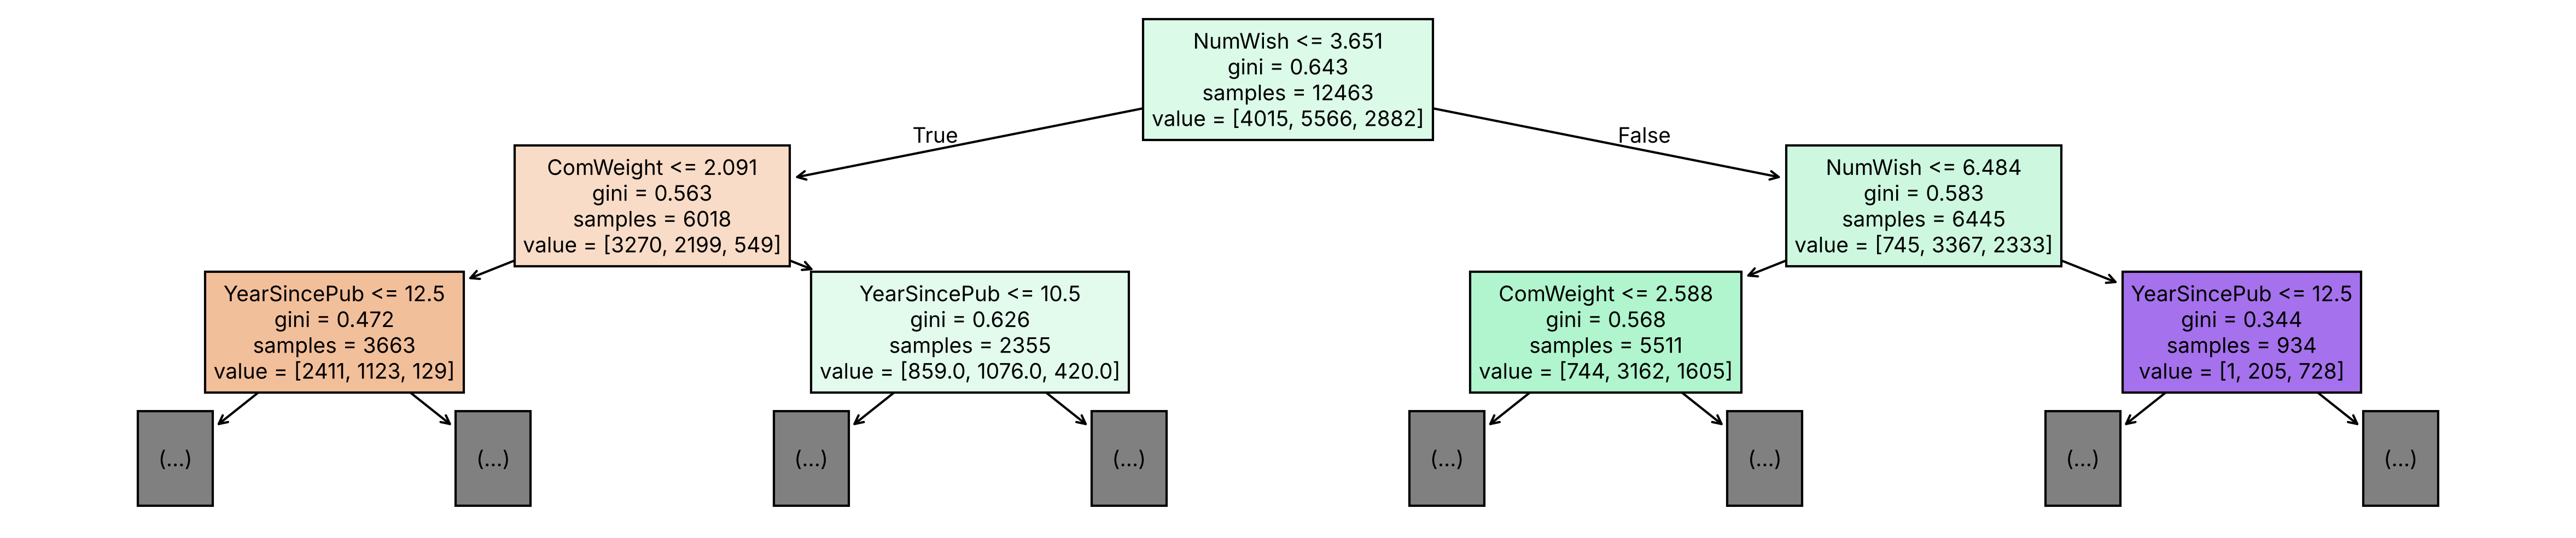

In [7]:

plt.figure(figsize=(20, 4), dpi=300)
plot_tree(dt, max_depth= 2,filled=True, feature_names= feature_tot)
plt.show()

In [8]:

y_train_pred = dt.predict(X_train)
y_test_pred = dt.predict(X_test)


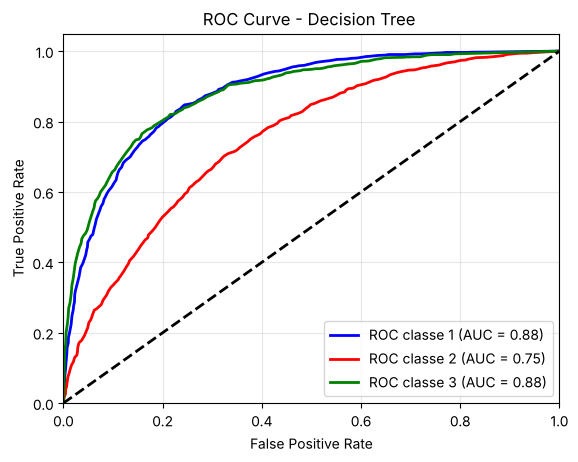

In [9]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
from itertools import cycle

# 1. (RI)ADDESTRAMENTO
# Ricreo e addestro il modello per essere sicuro che sia "fitted"
dt = DecisionTreeClassifier(max_depth=12, min_samples_leaf=50)
dt.fit(X_train, y_train)  # <--- Questo passaggio è fondamentale!

# 2. Preparazione dati ROC
classes = dt.classes_
n_classes = len(classes)
y_test_bin = label_binarize(y_test, classes=classes)

# 3. Ottenere le probabilità
y_score = dt.predict_proba(X_test)

# 4. Calcolo metriche
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# 5. Visualizzazione
plt.figure()
colors = cycle(['blue', 'red', 'green', 'orange'])

for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'ROC classe {classes[i]} (AUC = {roc_auc[i]:0.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Decision Tree ')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

In [10]:
print('Train Accuracy %s' % accuracy_score(y_train, y_train_pred))
print('Train F1-score %s' % f1_score(y_train, y_train_pred, average=None))
print()

print('Test Accuracy %s' % accuracy_score(y_test, y_test_pred))
print('Test F1-score %s' % f1_score(y_test, y_test_pred, average=None))

Train Accuracy 0.7012757762978417
Train F1-score [0.7400892  0.6895422  0.66755471]

Test Accuracy 0.6740072202166065
Test F1-score [0.70860556 0.66392389 0.64332855]


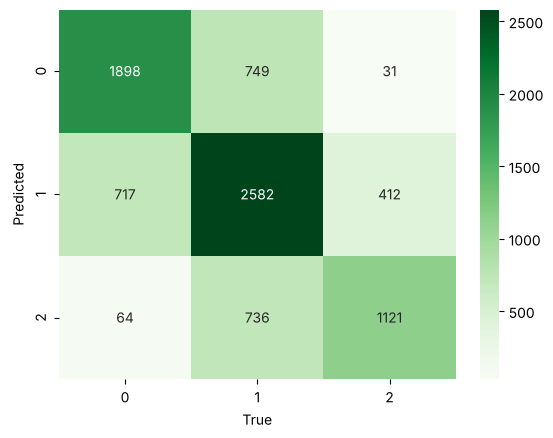

In [11]:
cf = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cf, annot=True, cmap="Greens", fmt= "d")
plt.xlabel("True")
plt.ylabel("Predicted")
plt.show()

In [12]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

# 1. Definiamo i parametri da testare
# Ho inserito valori sensati per il tuo dataset basandomi sui test precedenti
param_grid = {
    'max_depth': [3, 5, 7, 10, 12,14,16],
    'min_samples_leaf': [10, 20, 50, 100],
    'criterion': ['gini', 'entropy']
}

# 2. Creiamo il modello base
dt_base = DecisionTreeClassifier(random_state=42)

# 3. Configuriamo la ricerca automatica
# cv=5 significa che proverà ogni combinazione su 5 "fette" diverse di dati
grid_search = GridSearchCV(estimator=dt_base, 
                           param_grid=param_grid, 
                           cv=5, 
                           scoring='accuracy', 
                           verbose=1)

# 4. Lanciamo la ricerca sui dati di training
grid_search.fit(X_train, y_train)

# 5. Risultati
print(f"Migliori parametri trovati: {grid_search.best_params_}")
print(f"Migliore accuracy media in Cross-Validation: {grid_search.best_score_:.4f}")

# Ora puoi usare il modello "ottimizzato" per vedere la Test Accuracy finale
best_model = grid_search.best_estimator_
test_acc = best_model.score(X_test, y_test)
print(f"Accuracy finale sul Test Set: {test_acc:.4f}")

Fitting 5 folds for each of 56 candidates, totalling 280 fits

Migliori parametri trovati: {'criterion': 'gini', 'max_depth': 12, 'min_samples_leaf': 50}
Migliore accuracy media in Cross-Validation: 0.6649
Accuracy finale sul Test Set: 0.6740


Model Evaluation Strategy

The model was evaluated using a train-test split and validated with cross-validation (GridSearchCV) on the training set only, so that the test set stays unseen until the final evaluation.

- Search on accuracy: the best tree uses gini, max_depth=12 and min_samples_leaf=50 (CV accuracy 0.66, test accuracy 0.67).
- Search on macro F1 with stratified 5-fold cross-validation (below): max_depth=8 and min_samples_leaf=50 (CV macro F1 0.66, test macro F1 0.67).

Deeper trees reach a higher training accuracy, but cross-validation shows that a constrained tree (at least 50 samples per leaf) generalises better.

In [13]:
f1_macro = make_scorer(f1_score, average='macro')

In [14]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
dt = DecisionTreeClassifier(
    random_state=40
)
param_grid = {
    'max_depth': [5, 7, 8, 10, 12],
    'min_samples_leaf': [50, 100]
}
grid = GridSearchCV(
    estimator=dt,
    param_grid=param_grid,
    scoring=f1_macro,
    cv=cv,
    n_jobs=-1
)

# ricerca solo sul training set: il test set resta fuori fino alla valutazione finale
grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=40)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [5, 7, ...], 'min_samples_leaf': [50, 100]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",make_scorer(f...average=macro)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: 

In [15]:
print("Best parameters:", grid.best_params_)
print("Best CV F1-macro:", grid.best_score_)

Best parameters: {'max_depth': 8, 'min_samples_leaf': 50}
Best CV F1-macro: 0.660383027539261


In [16]:
from sklearn.metrics import classification_report

best_model = grid.best_estimator_

y_pred = best_model.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           1       0.72      0.68      0.70      2678
           2       0.63      0.73      0.67      3711
           3       0.73      0.57      0.64      1921

    accuracy                           0.67      8310
   macro avg       0.69      0.66      0.67      8310
weighted avg       0.68      0.67      0.67      8310



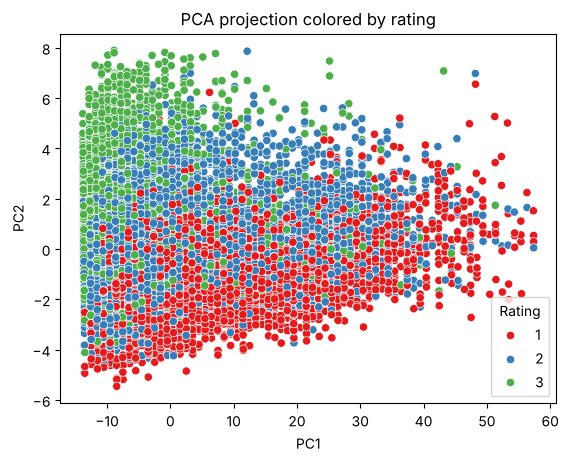

In [17]:
from sklearn.decomposition import PCA
current_year = 2026
df["CurrentYear"] = current_year - df["YearPublished"]
features = df[["CurrentYear","ComWeight","belong_to_family","NumOwned","NumWish"]]
pca = PCA(n_components=2)
components = pca.fit_transform(features)

df["PC1"] = components[:,0]
df["PC2"] = components[:,1]

sns.scatterplot(data=df, x="PC1", y="PC2", hue="Rating", palette="Set1")
plt.title("PCA projection colored by rating")
plt.show()